# Практическое занятие № 19. Нейрон, MLP, forward, BCE и backpropagation
**ТюмГУ · «Технологии искусственного интеллекта — 1» · 90 минут**  
Автор учебных материалов: В. А. Мазур, доцент ШКН ТюмГУ.

**Результат:** (1) реализовать прямой и обратный проход вручную на NumPy; (2) проверить градиенты численно; (3) обучить собственную MLP на учебном кейсе заказов; (4) сравнить с DummyClassifier. Студент обязан объяснить, откуда берутся градиенты и почему нельзя получать параметры нормализации из validation/test.

Файл `orders_dirty.csv` можно положить рядом с блокнотом. Для проверки запуска, если он недоступен, используйте приложенный `demo_orders_19_20.csv` — **отдельный синтетический** набор. В Google Colab загрузите нужные CSV на вкладке Files. Все результаты для демонабора являются только учебными.

## 1. Проверка окружения (0–7 мин)
Проверьте версии библиотек и установите случайное зерно. В графике нельзя выдавать демоданные за исходный набор студентов.

In [8]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Image
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
SEED=42
STUDENT='Сидоров'
GROUP='нет'
np.random.seed(SEED)
print(f'Студент: {STUDENT}; группа: {GROUP}; seed: {SEED}')
print('NumPy:',np.__version__,'pandas:',pd.__version__,'scikit-learn:',sklearn.__version__)

Студент: Сидоров; группа: нет; seed: 42
NumPy: 2.2.5 pandas: 2.2.3 scikit-learn: 1.9.1


## 2. Одиночный искусственный нейрон (7–17 мин)
\(z=x^\top w+b\), \(a=\sigma(z)=1/(1+e^{-z})\).

**Задание.** Для \(x=(2,1)\), \(w=(0.4,-0.2)\), \(b=-0.1\) вычислите \(z\) вручную, затем сравните с кодом. Объясните, почему нелинейность нужна между слоями.

In [2]:
def sigmoid(z):
    z=np.asarray(z,dtype=float)
    out=np.empty_like(z)
    positive=z>=0
    out[positive]=1/(1+np.exp(-z[positive]))
    ez=np.exp(z[~positive]); out[~positive]=ez/(1+ez)
    return out
x=np.array([2.,1.]); w=np.array([.4,-.2]); b=-.1
z=float(x@w+b);a=float(sigmoid(np.array([z]))[0])
print('z = 2·0.4 + 1·(-0.2) - 0.1 =',z)
print('a = sigmoid(z) =',a)
assert np.isclose(z,0.5) and np.isclose(a,0.6224593312018546)

z = 2·0.4 + 1·(-0.2) - 0.1 = 0.5000000000000001
a = sigmoid(z) = 0.6224593312018547


## 3. Пишем MLP без фреймворка (17–37 мин)
Архитектура: 2 входа → скрытый слой 6 нейронов с tanh → 1 выходной нейрон с sigmoid. 

\(Z_1=XW_1+b_1\), \(A_1=\tanh(Z_1)\), \(Z_2=A_1W_2+b_2\), \(P=\sigma(Z_2)\).  
\(L=-\frac{1}{n}\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]\).

При BCE+sigmoid \(\partial L/\partial Z_2=(P-Y)/n\). Далее применяем цепное правило. **Запрещено** заменять ручные производные на `torch.autograd` — это тема занятия 20.

In [3]:
def init_mlp(n_inputs=2,n_hidden=6,seed=42):
    r=np.random.default_rng(seed)
    return {'W1':r.normal(0,0.5,(n_inputs,n_hidden)),
            'b1':np.zeros((1,n_hidden)),
            'W2':r.normal(0,0.5,(n_hidden,1)),
            'b2':np.zeros((1,1))}

def forward(X,p):
    z1=X@p['W1']+p['b1']
    a1=np.tanh(z1)
    z2=a1@p['W2']+p['b2']
    yhat=sigmoid(z2)
    return yhat,{'X':X,'A1':a1,'Z1':z1,'Z2':z2}

def binary_loss(y,p):
    q=np.clip(p,1e-9,1-1e-9)
    return float(-np.mean(y*np.log(q)+(1-y)*np.log(1-q)))

def backward(y,yhat,cache,p):
    n=len(y)
    dz2=(yhat-y)/n
    dw2=cache['A1'].T@dz2
    db2=dz2.sum(axis=0,keepdims=True)
    dz1=(dz2@p['W2'].T)*(1-cache['A1']**2)
    dw1=cache['X'].T@dz1
    db1=dz1.sum(axis=0,keepdims=True)
    return {'W1':dw1,'b1':db1,'W2':dw2,'b2':db2}

X_xor=np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
y_xor=np.array([[0],[1],[1],[0]],dtype=float)
p=init_mlp()
yhat,cache=forward(X_xor,p)
grad=backward(y_xor,yhat,cache,p)
expected={'W1':(2,6),'b1':(1,6),'W2':(6,1),'b2':(1,1)}
assert {k:v.shape for k,v in p.items()}==expected
assert {k:v.shape for k,v in grad.items()}==expected
assert cache['Z1'].shape==cache['A1'].shape==(4,6)
assert cache['Z2'].shape==yhat.shape==(4,1)
print('Размерности параметров и градиентов:',expected)
print('XOR: X',X_xor.shape,'Z1/A1',cache['Z1'].shape,'Z2/ŷ',yhat.shape)
print('Начальная BCE:',binary_loss(y_xor,yhat))

Размерности параметров и градиентов: {'W1': (2, 6), 'b1': (1, 6), 'W2': (6, 1), 'b2': (1, 1)}
XOR: X (4, 2) Z1/A1 (4, 6) Z2/ŷ (4, 1)
Начальная BCE: 0.6989681209087988


## 4. Проверка градиента конечными разностями (37–49 мин)
Для каждого выбранного веса: \(g_{num}=[L(\theta+\varepsilon)-L(\theta-\varepsilon)]/(2\varepsilon)\). Сравните с аналитическим \(g_{analytical}\). Малое расхождение подтверждает корректность реализации, но не гарантирует правильность постановки ML-задачи.

In [4]:
def finite_diff(param,idx,X,y,p,eps=1e-5):
    old=p[param][idx]
    try:
        p[param][idx]=old+eps; lp=binary_loss(y,forward(X,p)[0])
        p[param][idx]=old-eps; lm=binary_loss(y,forward(X,p)[0])
    finally:
        p[param][idx]=old
    return (lp-lm)/(2*eps)
checks=[('W1',(0,0)),('W1',(1,2)),('b1',(0,1)),('W2',(2,0)),('b2',(0,0))]
rows=[]
for name,idx in checks:
    gn=finite_diff(name,idx,X_xor,y_xor,p)
    ga=float(grad[name][idx]); rel=abs(gn-ga)/max(1e-8,abs(gn)+abs(ga))
    rows.append([name,str(idx),gn,ga,rel])
res=pd.DataFrame(rows,columns=['tensor','index','numeric','analytic','relative_diff'])
display(res)
res.to_csv('19_gradient_checks.csv',index=False)
print('Максимальная относительная ошибка:',res.relative_diff.max())
assert len(res)>=5 and (res.relative_diff < 1e-5).all(), 'Проверьте backprop'

,tensor,index,numeric,analytic,relative_diff
0,W1,"(0, 0)",-0.001011,-0.001011,1.971240e-10
1,W1,"(1, 2)",-0.006776,-0.006776,2.712228e-10
2,b1,"(0, 1)",-0.018867,-0.018867,1.729664e-10
3,W2,"(2, 0)",-0.010075,-0.010075,4.486717e-10
4,b2,"(0, 0)",-0.029830,-0.029830,8.425123e-11


Максимальная относительная ошибка: 4.486717422671806e-10


## 5. Обучение на XOR и график потерь (49–59 мин)
Это демонстрация необходимости скрытого нелинейного слоя. **Задание:** попробуйте убрать `tanh` и прокомментируйте, что меняется.

,x1,x2,y,p_tanh,p_no_tanh
0,0,0,0,0.000315,0.5
1,0,1,1,0.999002,0.5
2,1,0,1,0.998932,0.5
3,1,1,0,0.001330,0.5


XOR BCE: tanh 0.0009283583114046644 ; без tanh 0.6931471805599454


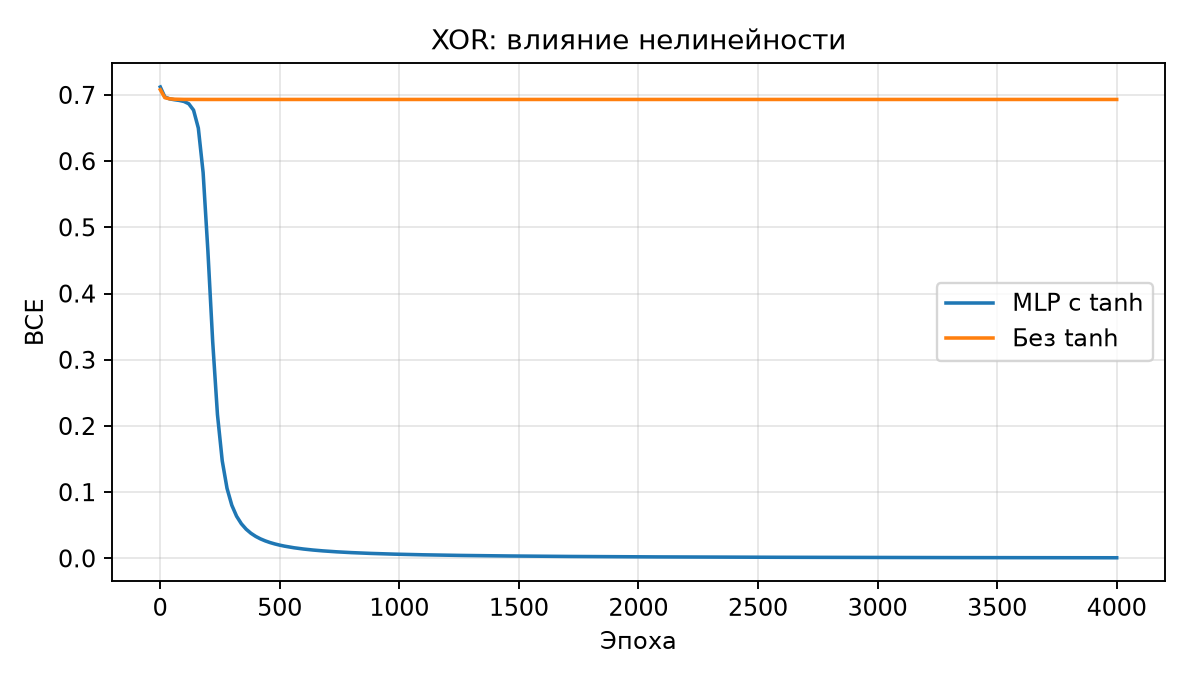

In [5]:
def train_xor(use_tanh=True,seed=7,epochs=4000,lr=0.45):
    weights=init_mlp(seed=seed)
    history=[]
    for epoch in range(1,epochs+1):
        pred,c=forward(X_xor,weights) if use_tanh else forward_linear_hidden(X_xor,weights)
        g=backward(y_xor,pred,c,weights) if use_tanh else backward_linear_hidden(y_xor,pred,c,weights)
        for k in weights:
            weights[k]-=lr*g[k]
        if epoch==1 or epoch%20==0:
            pr=(forward(X_xor,weights) if use_tanh else forward_linear_hidden(X_xor,weights))[0]
            history.append((epoch,binary_loss(y_xor,pr)))
    return weights,pd.DataFrame(history,columns=['epoch','BCE'])

def forward_linear_hidden(X,p):
    a1=X@p['W1']+p['b1']
    yhat=sigmoid(a1@p['W2']+p['b2'])
    return yhat,{'X':X,'A1':a1}

def backward_linear_hidden(y,yhat,c,p):
    dz2=(yhat-y)/len(y)
    dz1=dz2@p['W2'].T
    return {'W1':c['X'].T@dz1,'b1':dz1.sum(axis=0,keepdims=True),
            'W2':c['A1'].T@dz2,'b2':dz2.sum(axis=0,keepdims=True)}

p_xor,h_xor=train_xor(True)
p_linear,h_linear=train_xor(False)
pred_xor=forward(X_xor,p_xor)[0].ravel()
pred_linear=forward_linear_hidden(X_xor,p_linear)[0].ravel()
xor_results=pd.DataFrame({'x1':X_xor[:,0].astype(int),'x2':X_xor[:,1].astype(int),
                          'y':y_xor.ravel().astype(int),'p_tanh':pred_xor,'p_no_tanh':pred_linear})
display(xor_results)
print('XOR BCE: tanh',h_xor.BCE.iloc[-1],'; без tanh',h_linear.BCE.iloc[-1])
assert np.array_equal((pred_xor>=0.5).astype(int),y_xor.ravel().astype(int))
xor_results.to_csv('19_xor_predictions.csv',index=False)
h_xor.assign(model='tanh').to_csv('19_xor_history.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(h_xor.epoch,h_xor.BCE,label='MLP с tanh')
ax.plot(h_linear.epoch,h_linear.BCE,label='Без tanh')
ax.set(xlabel='Эпоха',ylabel='BCE',title='XOR: влияние нелинейности')
ax.grid(alpha=.3);ax.legend();fig.tight_layout()
fig.savefig('19_xor_learning.png',dpi=170);plt.close(fig)
display(Image(filename='19_xor_learning.png'))

## 6. Перенос ручной MLP на заказы (59–82 мин)
**Задание:** прогнозировать `late` по двум ранним числовым признакам `distance_km` и `queue_size`. Это упрощённая модель для проверки механики нейросети, не полноценное производственное решение. `actual_minutes`, `late`, `order_id` и сырой `created_at` в X не передавать.

Последовательность: аудит метки → исключение точного дубликата/противоречивой исторической метки → сортировка по времени → 60/20/20 → `SimpleImputer` и `StandardScaler`, **fit только train** → MLP на train → сравнение с DummyClassifier на validation. Test до выбора модели не открываем.

In [6]:
dataset=Path('orders_dirty.csv')
assert dataset.exists(),'Для основного эксперимента нужен orders_dirty.csv'
raw=pd.read_csv(dataset,encoding='utf-8-sig')
needed={'order_id','created_at','distance_km','queue_size','promised_minutes','actual_minutes','late'}
assert needed<=set(raw.columns),f'Отсутствуют поля: {needed-set(raw.columns)}'
print('Источник:',dataset.name,'Размер:',raw.shape,'Полные дубли:',int(raw.duplicated().sum()))
print('Повторяющиеся order_id:',int(raw.order_id.duplicated().sum()))
print('Пропуски в источнике:');display(raw[list(needed)].isna().sum().to_frame('count').T)
audit_rows=[]
for _,r in raw[raw.duplicated()].iterrows():
    audit_rows.append((r.order_id,'полный дубль','исключён'))
df=raw.drop_duplicates().copy()
distance_raw=df.distance_km.astype('string')
comma=distance_raw.str.contains(',',regex=False,na=False)
for oid in df.loc[comma,'order_id']:
    audit_rows.append((oid,'десятичная запятая distance_km','заменена точкой'))
df['distance_km']=pd.to_numeric(distance_raw.str.replace(',','.',regex=False),errors='coerce')
for col in ['queue_size','promised_minutes','actual_minutes','late']:
    df[col]=pd.to_numeric(df[col],errors='coerce')
for oid in df.loc[df.distance_km.isna(),'order_id']:
    audit_rows.append((oid,'нечисловой или пустой distance_km','медианная импутация по train'))
for oid in df.loc[df.queue_size.isna(),'order_id']:
    audit_rows.append((oid,'нечисловой или пустой queue_size','медианная импутация по train'))
for col in ['distance_km','queue_size']:
    bad=df[col]<0
    for oid in df.loc[bad,'order_id']:
        audit_rows.append((oid,f'отрицательное {col}','медианная импутация по train'))
    df.loc[bad,col]=np.nan
df['created_at']=pd.to_datetime(df.created_at,errors='coerce')
invalid=df.created_at.isna() | df.late.isna() | ~df.late.isin([0,1]) | df.order_id.isna()
for oid in df.loc[invalid,'order_id']:
    audit_rows.append((oid,'нет корректной даты, ID или метки','исключён'))
df=df.loc[~invalid].copy()
can_audit=df.actual_minutes.notna() & df.promised_minutes.notna()
derived=((df.actual_minutes-df.promised_minutes)>15).astype(int)
conflict=can_audit & df.late.ne(derived)
for oid in df.loc[conflict,'order_id']:
    audit_rows.append((oid,'late противоречит порогу actual-promised>15','исключён'))
df=df.loc[~conflict].copy()
assert df.order_id.is_unique,'Остались неоднозначные повторные ID'
audit_df=pd.DataFrame(audit_rows,columns=['order_id','issue','action'])
display(audit_df);audit_df.to_csv('19_cleaning_audit.csv',index=False)
df=df.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
n=len(df);ntr=int(n*.6);nval=int(n*.2)
assert ntr>=12 and nval>=6 and n-ntr-nval>=6
tr=df.iloc[:ntr].copy();va=df.iloc[ntr:ntr+nval].copy();te=df.iloc[ntr+nval:].copy()
assert not (set(tr.order_id)&set(va.order_id)|set(tr.order_id)&set(te.order_id)|set(va.order_id)&set(te.order_id))
assert tr.created_at.max()<=va.created_at.min()<=te.created_at.min()
cols=['distance_km','queue_size']
assert not set(cols)&{'actual_minutes','late','order_id','created_at'}
imp=SimpleImputer(strategy='median');sc=StandardScaler()
Xtr=sc.fit_transform(imp.fit_transform(tr[cols]))
Xva=sc.transform(imp.transform(va[cols]))
ytr=tr.late.to_numpy(dtype=float).reshape(-1,1)
yva=va.late.to_numpy(dtype=float).reshape(-1,1)
assert set(np.unique(ytr.ravel()))=={0,1}
split_summary=pd.DataFrame({'split':['train','validation','test'],
    'n':[len(tr),len(va),len(te)],
    'first_date':[tr.created_at.min(),va.created_at.min(),te.created_at.min()],
    'last_date':[tr.created_at.max(),va.created_at.max(),te.created_at.max()],
    'late_rate':[tr.late.mean(),va.late.mean(),te.late.mean()]})
display(split_summary);split_summary.to_csv('19_split_summary.csv',index=False)
print('Признаки:',cols,'; медианы train:',imp.statistics_,'; средние train:',sc.mean_)
print('Итог:',n,'записей; исходный CSV не изменён; test зарезервирован и в подборе модели не используется')

Источник: orders_dirty.csv Размер: (600, 10) Полные дубли: 1
Повторяющиеся order_id: 1
Пропуски в источнике:


,late,order_id,created_at,actual_minutes,queue_size,distance_km,promised_minutes
count,0,0,0,0,1,0,0


,order_id,issue,action
0,ORD-0020,полный дубль,исключён
1,ORD-0010,десятичная запятая distance_km,заменена точкой
2,ORD-0024,нечисловой или пустой distance_km,медианная импутация по train
3,ORD-0045,нечисловой или пустой queue_size,медианная импутация по train
4,ORD-0035,late противоречит порогу actual-promised>15,исключён


,split,n,first_date,last_date,late_rate
0,train,358,2026-08-25 08:00:00,2026-09-28 02:45:00,0.449721
1,validation,119,2026-09-28 03:36:00,2026-10-06 00:45:00,0.445378
2,test,121,2026-10-06 02:42:00,2026-10-15 05:06:00,0.545455


Признаки: ['distance_km', 'queue_size'] ; медианы train: [9. 9.] ; средние train: [9.14217877 9.76256983]
Итог: 598 записей; исходный CSV не изменён; test зарезервирован и в подборе модели не используется


,hidden,train_BCE,validation_BCE,min_validation_BCE,accuracy,F1
0,3,0.622877,0.615917,0.610465,0.638655,0.605505
1,6,0.620135,0.614290,0.609143,0.647059,0.611111
2,12,0.620198,0.611757,0.605210,0.638655,0.605505


,model,accuracy,F1
0,Dummy most_frequent,0.554622,0.000000
1,Ручная MLP (6),0.647059,0.611111


,learning_rate,train_BCE,validation_BCE,accuracy,F1
0,0.08,0.620135,0.614290,0.647059,0.611111
1,0.04,0.621005,0.610951,0.647059,0.611111


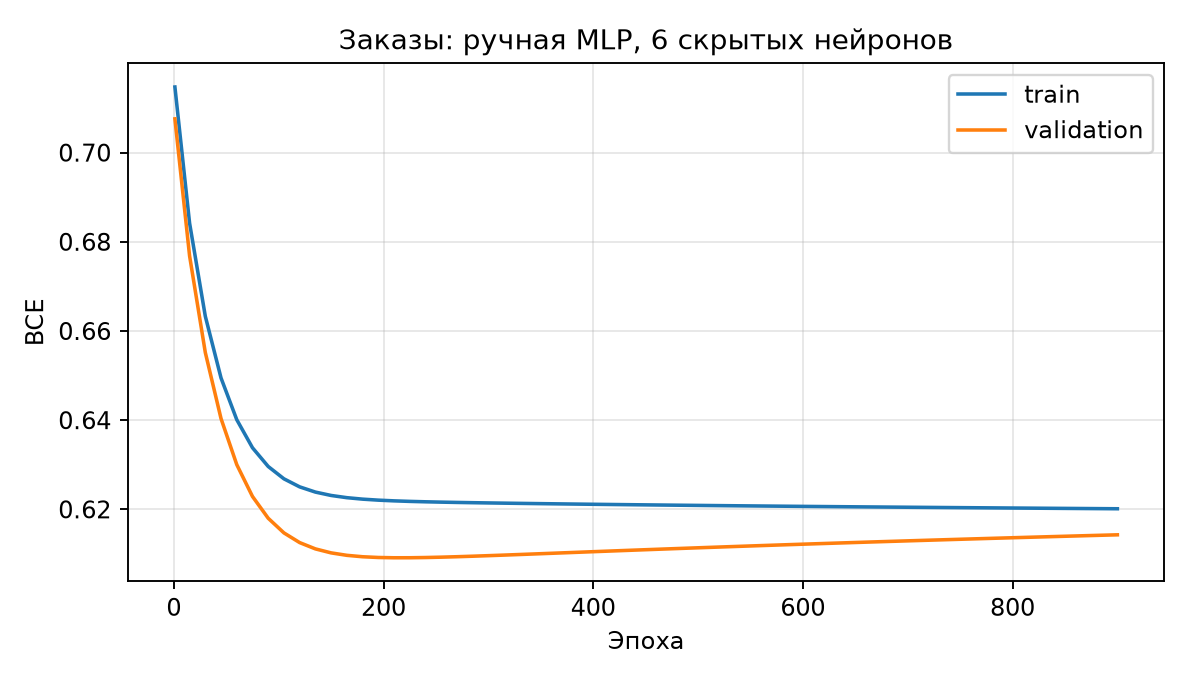

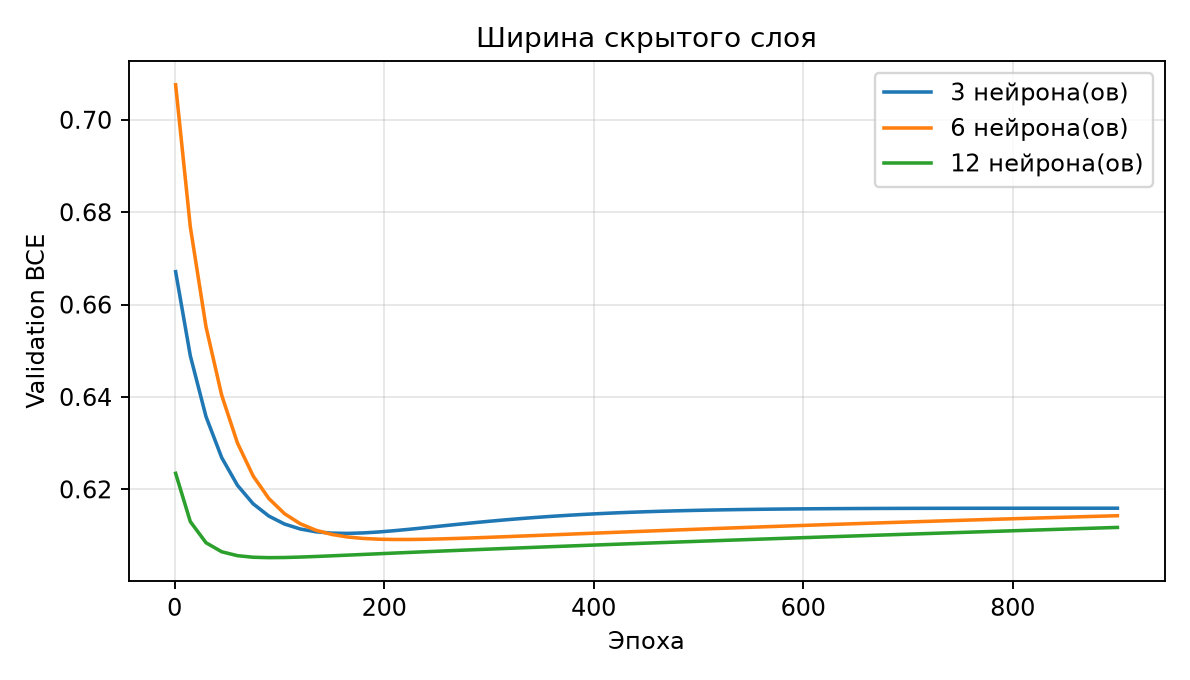

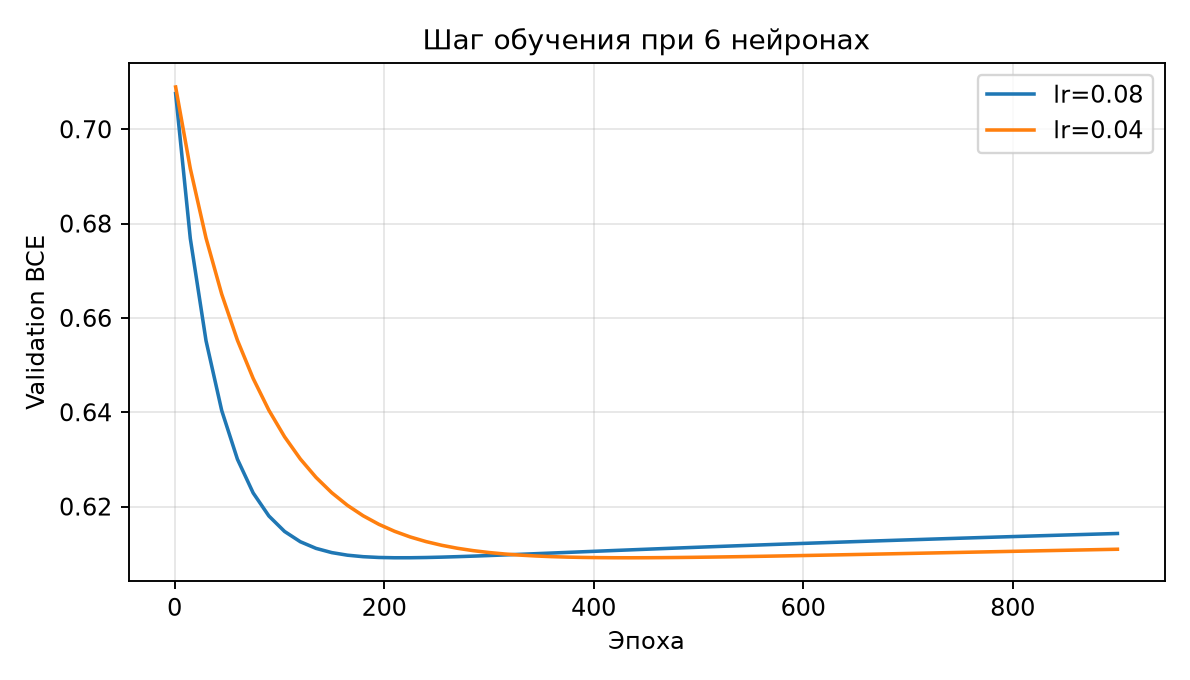

Все метрики рассчитаны на validation; test не использован при подборе.


In [7]:
def train_orders(hidden=6,lr=.08,epochs=900,seed=42):
    model=init_mlp(n_hidden=hidden,seed=seed)
    history=[]
    for step in range(1,epochs+1):
        pt,cache=forward(Xtr,model)
        grads=backward(ytr,pt,cache,model)
        for k in model:
            model[k]-=lr*grads[k]
        if step==1 or step%15==0:
            history.append((step,binary_loss(ytr,forward(Xtr,model)[0]),
                            binary_loss(yva,forward(Xva,model)[0])))
    return model,pd.DataFrame(history,columns=['epoch','train_BCE','validation_BCE'])

models={};histories={};width_rows=[]
for width in [3,6,12]:
    models[width],histories[width]=train_orders(hidden=width)
    pv=forward(Xva,models[width])[0].ravel()
    h=histories[width]
    width_rows.append((width,h.train_BCE.iloc[-1],h.validation_BCE.iloc[-1],
                       h.validation_BCE.min(),accuracy_score(yva.ravel(),pv>=.5),
                       f1_score(yva.ravel(),pv>=.5,zero_division=0)))
width_metrics=pd.DataFrame(width_rows,columns=['hidden','train_BCE','validation_BCE','min_validation_BCE','accuracy','F1'])
display(width_metrics);width_metrics.to_csv('19_width_metrics.csv',index=False)

dummy=DummyClassifier(strategy='most_frequent').fit(Xtr,ytr.ravel())
pdummy=dummy.predict(Xva)
pmlp=forward(Xva,models[6])[0].ravel()
validation_metrics=pd.DataFrame([
    ('Dummy most_frequent',accuracy_score(yva.ravel(),pdummy),f1_score(yva.ravel(),pdummy,zero_division=0)),
    ('Ручная MLP (6)',accuracy_score(yva.ravel(),pmlp>=.5),f1_score(yva.ravel(),pmlp>=.5,zero_division=0))],
    columns=['model','accuracy','F1'])
display(validation_metrics);validation_metrics.to_csv('19_validation_metrics.csv',index=False)

half_model,half_history=train_orders(hidden=6,lr=.04)
half_pred=forward(Xva,half_model)[0].ravel()
lr_metrics=pd.DataFrame([
    (0.08,histories[6].train_BCE.iloc[-1],histories[6].validation_BCE.iloc[-1],
     accuracy_score(yva.ravel(),pmlp>=.5),f1_score(yva.ravel(),pmlp>=.5,zero_division=0)),
    (0.04,half_history.train_BCE.iloc[-1],half_history.validation_BCE.iloc[-1],
     accuracy_score(yva.ravel(),half_pred>=.5),f1_score(yva.ravel(),half_pred>=.5,zero_division=0))],
    columns=['learning_rate','train_BCE','validation_BCE','accuracy','F1'])
display(lr_metrics);lr_metrics.to_csv('19_lr_metrics.csv',index=False)

def save_plot(filename,draw):
    fig,ax=plt.subplots(figsize=(7,4))
    draw(ax)
    ax.grid(alpha=.3);ax.legend();fig.tight_layout()
    fig.savefig(filename,dpi=170);plt.close(fig)
    display(Image(filename=filename))

def draw_learning(ax):
    h=histories[6]
    ax.plot(h.epoch,h.train_BCE,label='train')
    ax.plot(h.epoch,h.validation_BCE,label='validation')
    ax.set(xlabel='Эпоха',ylabel='BCE',title='Заказы: ручная MLP, 6 скрытых нейронов')
save_plot('19_orders_learning.png',draw_learning)

def draw_width(ax):
    for width in [3,6,12]:
        h=histories[width];ax.plot(h.epoch,h.validation_BCE,label=f'{width} нейрона(ов)')
    ax.set(xlabel='Эпоха',ylabel='Validation BCE',title='Ширина скрытого слоя')
save_plot('19_width_comparison.png',draw_width)

def draw_lr(ax):
    ax.plot(histories[6].epoch,histories[6].validation_BCE,label='lr=0.08')
    ax.plot(half_history.epoch,half_history.validation_BCE,label='lr=0.04')
    ax.set(xlabel='Эпоха',ylabel='Validation BCE',title='Шаг обучения при 6 нейронах')
save_plot('19_lr_comparison.png',draw_lr)
print('Все метрики рассчитаны на validation; test не использован при подборе.')

## 7. Самостоятельная часть и сдача (82–90 мин)
1. Измените ширину скрытого слоя с 6 до 3 и 12, сравните графики на **validation** (не test).
2. Проверьте аналитические градиенты как минимум в пяти точках (укажите максимальную относительную ошибку).
3. Объясните в 5–7 предложениях: что означает BCE, где используется цепное правило и почему градиенты нельзя вычислять из округлённых классов.
4. Представьте `19_student.ipynb`, отчёт `Группа_Фамилия_З19_Отчет.docx` (2–4 страницы) с формулами, таблицами, двумя графиками и ограничениями.

**Оценивание (10 баллов):** нейрон/формулы — 2; правильный forward/backprop — 3; gradient check — 2; эксперимент на заказах и baseline — 2; отчёт и воспроизводимость — 1.

**Контрольные вопросы:** Зачем нужна нелинейность? Чем логиты отличаются от вероятностей? Почему среднее берётся по всем объектам? Что случится, если масштабировать train+validation вместе?

### Ответы на вопросы ноутбука

**Раздел 2.** Для заданного нейрона $z=2\cdot0{,}4+1\cdot(-0{,}2)-0{,}1=0{,}5$; после sigmoid $a=0{,}622459$. $z$ — логит, то есть значение до активации; $a$ — число от 0 до 1, интерпретируемое как оценка вероятности положительного класса. Класс получается только после применения порога, здесь $a\geq0{,}5$. Нелинейная активация между слоями нужна, чтобы их последовательность не сводилась к одному линейному преобразованию и могла описывать нелинейные зависимости, например XOR.

**Раздел 5.** При `tanh` сеть верно распознаёт все четыре комбинации XOR: вероятности для классов 0 близки к нулю, для классов 1 — к единице. Без `tanh` два линейных преобразования сводятся к одному, поэтому модель остаётся линейной и выдаёт примерно 0,5 на всех четырёх комбинациях. Её BCE не преодолевает уровень $\ln 2\approx 0{,}693$, что видно на графике.

**Самостоятельная часть, п. 1.** При одинаковом разбиении, зерне 42, шаге 0,08 и 900 эпохах итоговая validation BCE составляет 0,6159 (3 нейрона), 0,6143 (6) и 0,6118 (12). У 12 нейронов BCE чуть ниже, но F1 у 6 нейронов чуть выше (0,6111 против 0,6055). По этим близким результатам нельзя уверенно утверждать, что увеличение ширины улучшает обобщение; сравнение выполнено только на validation, test сохранён.

**П. 2.** Для пяти параметров из всех четырёх тензоров на XOR аналитические градиенты сопоставлены с центральными конечными разностями. Максимальная относительная ошибка равна $4{,}49\cdot10^{-10}$, что меньше порога $10^{-5}$. Проверка подтверждает согласованность реализации backprop для выбранных точек.

**П. 3.** BCE измеряет ошибку вероятностного прогноза для двух классов и сильнее штрафует уверенные неверные вероятности. В прямом проходе сеть последовательно вычисляет линейные преобразования, `tanh` и `sigmoid`. При обратном проходе цепное правило переносит производную функции потерь от выхода через $W_2$ и производную `tanh` к $W_1$. Деление на число объектов соответствует усреднению BCE по выборке. Если округлить вероятность до 0 или 1 перед вычислением градиента, почти всюду получится нулевая производная по логиту; кроме того, уверенность модели исчезнет. Поэтому обучение и BCE используют непрерывные вероятности, а порог 0,5 применяется только для Accuracy и F1.

**Изменение шага обучения.** При шаге 0,04 после 900 эпох train BCE равна 0,6210 против 0,6201 при шаге 0,08; меньший шаг продвигается медленнее по train. Validation BCE при этом 0,6110 против 0,6143, а Accuracy и F1 совпадают. В показанном диапазоне обе кривые устойчивы, поэтому уменьшение шага не даёт выигрыша по классификационным метрикам и требует больше итераций для сопоставимого изменения весов.

**Ограничения и утечки.** Небольшой синтетический набор может плохо отражать реальные маршруты и сезонность; его искусственная зависимость метки может завышать переносимость результата; отдельные временные интервалы содержат мало наблюдений для устойчивой оценки. Утечка возникла бы при включении `actual_minutes` в признаки, поскольку это итог заказа после момента прогноза. Вторая утечка возникла бы при подгонке медиан и масштаба на train вместе с validation/test: сведения о будущих объектах повлияли бы на подготовку train. Дополнительно полный дубликат и противоречивую метку исключили до разбиения, а test не использовали для выбора ширины или шага.